# 03 — QC NSRDB & agregasi per jam + uji penyelarasan waktu (T08, T09)

| Bagian | Isi | Checklist |
|---|---|---|
| 1 | Baca & gabung 5 CSV, DatetimeIndex UTC | T08.1 |
| 2 | Duplikat & lubang timestamp | T08.2 |
| 3 | Tabulasi `fill_flag` | T08.3 |
| 4 | Cek fisis | T08.5 |
| 5 | **Konvensi timestamp dari data** (hari cerah vs posisi matahari) | T08.4, T09.1–T09.2 |
| 6 | Agregasi per jam, label period-ending, valid bila ≥5/6 sampel | T08.6 |
| 7 | Uji korelasi per pergeseran −2..+2 jam (data per jam) | T09.3 |
| 8 | Plot hari cerah + simpan parquet & laporan QC | T08.7, T09.4 |

Keluaran: `data/interim/nsrdb_hourly.parquet`, `results/qc_*.csv`, `figures/qc_*.png`. Angka-angka di sini masuk laporan data (T14).

## 0. Setup

In [1]:
# %pip install -q pandas numpy pvlib pyarrow matplotlib pyyaml
import io, json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, yaml
import pvlib

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CFG = yaml.safe_load(open(ROOT / "configs" / "config.yaml"))
RAW, INTERIM = ROOT / "data/raw", ROOT / "data/interim"
FIG, RES = ROOT / "figures", ROOT / "results"
for d in (INTERIM, FIG, RES):
    d.mkdir(parents=True, exist_ok=True)

LAT, LON = CFG["location"]["lat"], CFG["location"]["lon"]
ELEV = CFG["location"]["elevation_m"] or 0
YEARS, STEP = CFG["data"]["years"], int(CFG["data"]["nsrdb_interval_min"])
ZMAX = CFG["physics"]["zenith_max_deg"]
print(f"({LAT}, {LON}), elev {ELEV} m, {YEARS}, interval {STEP} menit")

## 1. Baca & gabung (T08.1)

In [2]:
def read_nsrdb(p):
    lines = p.read_text().splitlines()
    meta = dict(zip(lines[0].split(","), lines[1].split(",")))
    df = pd.read_csv(io.StringIO("\n".join(lines[2:])))
    df.index = pd.to_datetime(df[["Year", "Month", "Day", "Hour", "Minute"]]).dt.tz_localize("UTC")
    df = df.drop(columns=["Year", "Month", "Day", "Hour", "Minute"])
    df.columns = [c.strip().lower().replace(" ", "_") for c in df.columns]
    return meta, df

parts, META = [], None
for y in YEARS:
    META, d = read_nsrdb(RAW / f"nsrdb_{y}.csv")
    parts.append(d)
raw = pd.concat(parts).sort_index()
raw.index.name = "time_utc"
print("Kolom:", list(raw.columns))
print(f"{len(raw):,} baris, {raw.index.min()} s.d. {raw.index.max()}")
print("Grid NSRDB:", META.get("Latitude"), META.get("Longitude"), "| elev", META.get("Elevation"))

Kolom: ['ghi', 'dni', 'dhi', 'clearsky_ghi', 'clearsky_dni', 'clearsky_dhi', 'solar_zenith_angle', 'cloud_type', 'temperature', 'relative_humidity', 'dew_point', 'aerosol_optical_depth', 'fill_flag']
263,088 baris, 2016-01-01 00:00:00+00:00 s.d. 2020-12-31 23:50:00+00:00
Grid NSRDB: -6.88 107.61 | elev 770


## 2. Duplikat & lubang (T08.2)

In [3]:
full = pd.date_range(raw.index.min(), raw.index.max(), freq=f"{STEP}min", tz="UTC")
dups = raw.index.duplicated()
missing = full.difference(raw.index)
gap = pd.DataFrame({
    "duplikat": pd.Series(raw.index[dups].year).value_counts(),
    "timestamp_hilang": pd.Series(missing.year).value_counts(),
}).reindex(YEARS).fillna(0).astype(int)
gap.index.name = "tahun"
raw = raw[~dups].reindex(full)            # lubang menjadi NaN, bukan diisi
raw.index.name = "time_utc"
gap

,duplikat,timestamp_hilang
tahun,,
2016,0,0
2017,0,0
2018,0,0
2019,0,0
2020,0,0


## 3. `fill_flag` (T08.3) — dihitung pada jam siang (zenit < 85°)

In [4]:
day = raw["solar_zenith_angle"] < ZMAX
ff = (raw.loc[day, "fill_flag"].groupby(raw.index[day].year)
      .value_counts(normalize=True).mul(100).round(2).unstack(fill_value=0))
ff["%_terisi_(≠0)"] = 100 - ff.get(0, 0)
ff.index.name = "tahun"
print("Kode fill_flag: 0 = tidak diisi; selain 0 = nilai hasil pengisian (lihat dokumentasi NSRDB).")
print("Pemicu risiko #7 / keputusan #10: > 5% jam siang terisi dalam satu tahun.")
ff

Kode fill_flag: 0 = tidak diisi; selain 0 = nilai hasil pengisian (lihat dokumentasi NSRDB).
Pemicu risiko #7 / keputusan #10: > 5% jam siang terisi dalam satu tahun.


fill_flag,0,1,3,5,%_terisi_(≠0)
tahun,,,,,
2016,81.98,1.72,14.56,1.73,18.02
2017,83.14,1.71,13.77,1.39,16.86
2018,83.24,2.15,13.21,1.40,16.76
2019,83.81,1.88,12.85,1.46,16.19
2020,85.50,1.63,12.01,0.86,14.50


In [5]:
FILL_FLAG_POLICY = "keep_flag"     # "drop" | "keep_flag" — putuskan dari tabel di atas, catat di decisions.md
print("Kebijakan:", FILL_FLAG_POLICY)

Kebijakan: keep_flag


## 4. Cek fisis (T08.5)

In [6]:
z = raw["solar_zenith_angle"]
phys = pd.DataFrame({
    "GHI<0":                 raw["ghi"] < 0,
    "GHI>0 saat zenit>90":   (raw["ghi"] > 0) & (z > 90),
    "GHI>1.2×clearsky":      (raw["ghi"] > 1.2 * raw["clearsky_ghi"]) & (raw["clearsky_ghi"] > 50),
    "DHI>GHI":               (raw["dhi"] > raw["ghi"] + 5) & (z < ZMAX),
}).groupby(raw.index.year).sum()
phys.index.name = "tahun"
phys

,GHI<0,GHI>0 saat zenit>90,GHI>1.2×clearsky,DHI>GHI
tahun,,,,
2016,0,0,0,0
2017,0,0,0,0
2018,0,0,0,0
2019,0,0,0,0
2020,0,0,0,0


## 5. Konvensi timestamp dari data (T08.4, T09.1–T09.2)
Pada sampel cerah (cloud_type 0/1, fill_flag 0, k_c NSRDB 0,8–1,2), GHI terukur harus sejalan dengan posisi matahari. Kurva clear-sky sederhana (Haurwitz, hanya bergantung zenit) dihitung pada `timestamp + Δ` untuk Δ = −15…+15 menit; Δ dengan korelasi tertinggi menunjukkan waktu efektif pengukuran.
- Δ ≈ 0 → nilai **instan pada timestamp**
- Δ ≈ +5 → nilai mewakili **interval 10 menit yang dimulai di timestamp** (pusatnya +5 menit)

cloud_type (siang): {0: 22641, 1: 6217, 2: 6651, 3: 14666, 4: 3326, 6: 14015, 7: 39505, 8: 6887, 9: 2437}
28,018 sampel cerah dari 1376 hari
Δ terbaik = +1 menit (r = 0.9970); r(Δ=0) = 0.9969, r(Δ=+5) = 0.9962
Konvensi: instant


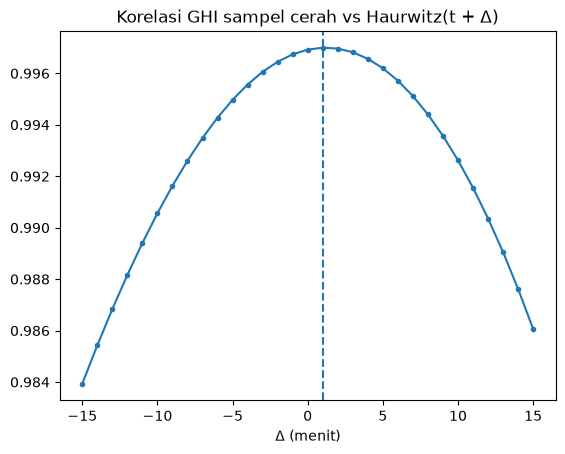

108 hari dengan siang cerah | per bulan: {1: 2, 4: 4, 5: 5, 6: 14, 7: 32, 8: 28, 9: 18, 10: 3, 11: 1, 12: 1}


In [7]:
dd = raw.copy()
dd["date"] = dd.index.normalize()
print("cloud_type (siang):", dd.loc[dd["solar_zenith_angle"] < 80, "cloud_type"].value_counts().sort_index().to_dict())

CLEAR_CODES = [0, 1]                     # 0 = clear, 1 = probably clear (kode NSRDB)
kc_n = dd["ghi"] / dd["clearsky_ghi"]
clear_mask = (dd["cloud_type"].isin(CLEAR_CODES) & (dd["fill_flag"] == 0)
              & (dd["solar_zenith_angle"] < 80) & kc_n.between(0.8, 1.2))
cs = dd[clear_mask].dropna(subset=["ghi"])
print(f"{len(cs):,} sampel cerah dari {cs['date'].nunique()} hari")

corr = {}
for s in range(-15, 16):
    sp = pvlib.solarposition.get_solarposition(cs.index + pd.Timedelta(minutes=s), LAT, LON, altitude=ELEV)
    ghi_cs = pvlib.clearsky.haurwitz(sp["apparent_zenith"])["ghi"].to_numpy()
    corr[s] = np.corrcoef(cs["ghi"].to_numpy(), ghi_cs)[0, 1]
corr = pd.Series(corr, name="r")
DELTA = int(corr.idxmax())
print(f"Δ terbaik = {DELTA:+d} menit (r = {corr.max():.4f}); r(Δ=0) = {corr[0]:.4f}, r(Δ=+5) = {corr[5]:.4f}")
CONVENTION = "instant" if abs(DELTA) <= 2 else ("period_start" if 3 <= DELTA <= 7 else "TIDAK JELAS — periksa")
print("Konvensi:", CONVENTION)
ax = corr.plot(marker=".", title="Korelasi GHI sampel cerah vs Haurwitz(t + Δ)")
ax.axvline(DELTA, ls="--"); ax.set_xlabel("Δ (menit)")
plt.savefig(FIG / "qc_timestamp_shift.png", dpi=150, bbox_inches="tight"); plt.show()

# Hari dengan jendela ±90 menit sekitar tengah hari seluruhnya cerah (untuk T09.2 & plot)
dates = pd.DatetimeIndex(dd["date"].unique())
transit = pvlib.solarposition.sun_rise_set_transit_spa(dates, LAT, LON)["transit"].dt.tz_convert("UTC")
CLEAR_DAYS = []
for d0, tr in transit.items():
    w = dd.loc[tr - pd.Timedelta(minutes=90): tr + pd.Timedelta(minutes=90)]
    if len(w) >= 16 and clear_mask.loc[w.index].all():
        CLEAR_DAYS.append(d0)
CLEAR_DAYS = pd.DatetimeIndex(CLEAR_DAYS)
print(f"{len(CLEAR_DAYS)} hari dengan siang cerah | per bulan:",
      pd.Series(CLEAR_DAYS.month).value_counts().sort_index().to_dict())

if len(CLEAR_DAYS) == 0:        # cadangan untuk plot: 4 hari dengan sampel cerah terbanyak
    CLEAR_DAYS = pd.DatetimeIndex(sorted(cs["date"].value_counts().index[:4]))


In [8]:
# T09.2: puncak GHI 10 menit vs tengah hari matahari (≤ 15 menit) pada hari siang-cerah
rows = []
for d0, tr in transit.items():
    if d0 not in CLEAR_DAYS:
        continue
    g = dd.loc[tr - pd.Timedelta(minutes=90): tr + pd.Timedelta(minutes=90), "ghi"]
    t_peak = g.idxmax() + pd.Timedelta(minutes=DELTA)
    rows.append({"tanggal": d0.date(), "puncak_utc": t_peak.time(), "solar_noon_utc": tr.time(),
                 "selisih_menit": (t_peak - tr).total_seconds() / 60})
noon = pd.DataFrame(rows, columns=["tanggal", "puncak_utc", "solar_noon_utc", "selisih_menit"])
if noon.empty:
    print("⚠ Tidak ada hari dengan siang cerah ±90 menit; T09.2 diwakili uji Δ di atas.")
    med = float("nan")
else:
    print(noon["selisih_menit"].describe().round(1))
    med = noon["selisih_menit"].abs().median()
    print("T09.2", "LULUS ✓" if med <= 15 else "GAGAL ✗", f"(median |selisih| = {med:.1f} menit, n = {len(noon)})")


count    108.0
mean      -2.3
std        4.6
min      -16.3
25%       -4.9
50%       -2.6
75%        0.7
max        6.6
Name: selisih_menit, dtype: float64
T09.2 LULUS ✓ (median |selisih| = 4.0 menit, n = 108)


## 6. Agregasi per jam, label period-ending (T08.6)
Waktu efektif = timestamp + Δ. Jam berlabel **H** = rata-rata sampel dengan waktu efektif di (H−1, H]. Jam valid bila ≥ 5 dari 6 sampel ada.

In [9]:
x = raw.copy()
if FILL_FLAG_POLICY == "drop":
    x.loc[x["fill_flag"] != 0, ["ghi", "dni", "dhi"]] = np.nan
x.index = x.index + pd.Timedelta(minutes=DELTA)

num = [c for c in x.columns if c not in ("cloud_type", "fill_flag")]
rs = dict(rule="1h", closed="right", label="right")
hourly = x[num].resample(**rs).mean()
n_valid = x["ghi"].resample(**rs).count()
hourly.loc[n_valid < 5, num] = np.nan
hourly["n_samples"] = n_valid
hourly["cloud_type_mode"] = x["cloud_type"].resample(**rs).agg(lambda s: s.mode().iloc[0] if s.notna().any() else np.nan)
hourly["fill_frac"] = (x["fill_flag"] != 0).resample(**rs).mean()
hourly = hourly[(hourly.index.year >= YEARS[0]) & (hourly.index.year <= YEARS[-1])]
hourly.index.name = "time_utc_period_ending"

day_h = hourly["solar_zenith_angle"] < ZMAX
miss = (hourly.loc[day_h, "ghi"].isna()
        .groupby([hourly.index[day_h].year, hourly.index[day_h].month]).mean().mul(100).round(2).unstack())
miss.index.name = "tahun"
print(f"{len(hourly):,} jam; % jam siang hilang per tahun × bulan:")
miss

43,847 jam; % jam siang hilang per tahun × bulan:


time_utc_period_ending,1,2,3,4,5,6,7,8,9,10,11,12
tahun,,,,,,,,,,,,
2016,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2017,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2018,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2019,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2020,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [10]:
# Flag per jam (keputusan #10): kode 1/3 (dan 2/4/6) = interpolasi, kode 5 = dipotong ke clear-sky
INTERP_CODES = [1, 2, 3, 4, 6]
hourly["interp_frac"] = x["fill_flag"].isin(INTERP_CODES).resample(**rs).mean().reindex(hourly.index)
hourly["capped_frac"] = (x["fill_flag"] == 5).resample(**rs).mean().reindex(hourly.index)

d = raw[raw["solar_zenith_angle"] < ZMAX]
by_hour = (d["fill_flag"].groupby((d.index.hour + 7) % 24)
           .value_counts(normalize=True).mul(100).round(1).unstack(fill_value=0))
by_hour.index.name = "jam WIB"
display(by_hour)
dh = hourly[day_h]
excl = dh["interp_frac"] > 1/6 + 1e-9
print("% jam siang dikecualikan dari evaluasi (≥2/6 sampel interpolasi):",
      excl.groupby(dh.index.year).mean().mul(100).round(1).to_dict())
e = dh["ghi"].groupby([dh.index.year, excl]).sum().unstack()
print("% energi GHI siang dikecualikan:", (e.get(True, 0) / e.sum(axis=1) * 100).round(1).to_dict())

fill_flag,0,1,3,5
jam WIB,,,,
5,17.6,0.0,68.4,13.9
6,48.0,0.3,47.8,3.8
7,93.7,0.5,5.1,0.7
8,94.3,0.5,5.1,0.1
9,75.4,16.8,7.8,0.0
10,87.5,0.4,12.2,0.0
11,88.3,0.4,11.3,0.0
12,92.3,0.3,7.4,0.0
13,94.9,0.3,4.8,0.0


% jam siang dikecualikan dari evaluasi (≥2/6 sampel interpolasi): {2016: 22.9, 2017: 21.3, 2018: 21.5, 2019: 21.0, 2020: 18.2}
% energi GHI siang dikecualikan: {2016: 16.0, 2017: 14.4, 2018: 15.9, 2019: 16.3, 2020: 10.5}


## 7. Uji penyelarasan per jam (T09.3): korelasi obs vs clear-sky maksimum di pergeseran 0

In [11]:
h = hourly[day_h].dropna(subset=["ghi", "clearsky_ghi"])   # jam siang saja
lag = {k: h["ghi"].corr(hourly["clearsky_ghi"].shift(k).reindex(h.index)) for k in range(-2, 3)}
lag = pd.Series(lag, name="r")
print(lag.round(4))
T09_3 = int(lag.idxmax()) == 0
print("T09.3", "LULUS ✓" if T09_3 else "GAGAL ✗ — HENTIKAN pekerjaan hilir (risiko #4)")

-2    0.5701
-1    0.7735
 0    0.8069
 1    0.5948
 2    0.2885
Name: r, dtype: float64
T09.3 LULUS ✓


## 8. Plot hari cerah + simpan (T08.7, T09.4)

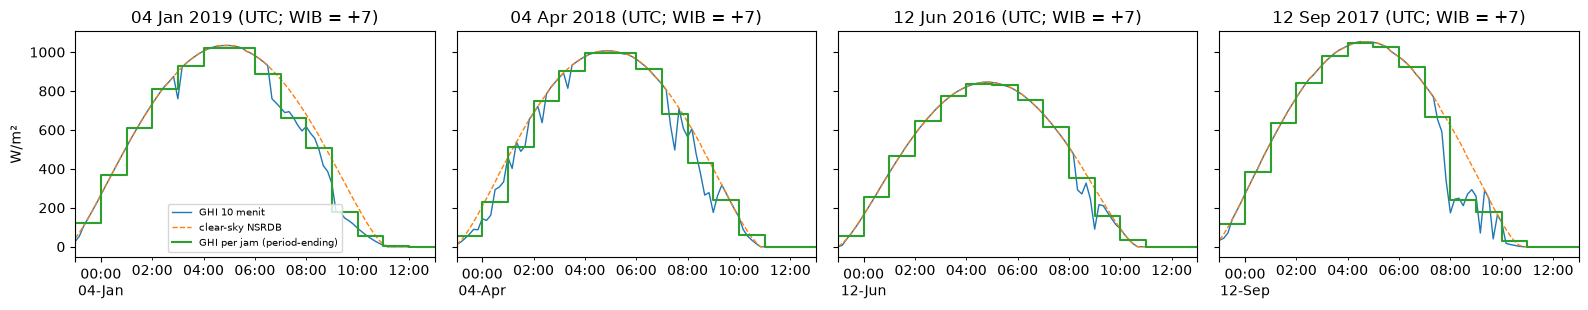

In [12]:
sample_days = pd.DatetimeIndex(CLEAR_DAYS).to_series().groupby(lambda d: d.month % 12 // 3).first().iloc[:4]
fig, axes = plt.subplots(1, len(sample_days), figsize=(4 * len(sample_days), 3.2), sharey=True)
axes = np.atleast_1d(axes)
for ax, d0 in zip(axes, sample_days):
    w = slice(d0 - pd.Timedelta(hours=1), d0 + pd.Timedelta(hours=13))
    raw.loc[w, "ghi"].plot(ax=ax, lw=1, label="GHI 10 menit")
    raw.loc[w, "clearsky_ghi"].plot(ax=ax, lw=1, ls="--", label="clear-sky NSRDB")
    hourly.loc[w, "ghi"].plot(ax=ax, drawstyle="steps-pre", label="GHI per jam (period-ending)")
    ax.set_title(f"{d0:%d %b %Y} (UTC; WIB = +7)"); ax.set_xlabel("")
axes[0].set_ylabel("W/m²"); axes[0].legend(fontsize=7)
plt.tight_layout(); plt.savefig(FIG / "qc_clear_days.png", dpi=150, bbox_inches="tight"); plt.show()

In [13]:
hourly.to_parquet(INTERIM / "nsrdb_hourly.parquet")
gap.to_csv(RES / "qc_gaps.csv"); ff.to_csv(RES / "qc_fill_flag.csv"); phys.to_csv(RES / "qc_physics.csv")
miss.to_csv(RES / "qc_missing_daytime_hours.csv"); noon.to_csv(RES / "qc_solar_noon.csv", index=False)

summary = {
    "nsrdb_grid": [META.get("Latitude"), META.get("Longitude")], "elev_m": META.get("Elevation"),
    "clear_samples": int(len(cs)), "clear_noon_days": int(len(CLEAR_DAYS)), "delta_min": DELTA, "convention": CONVENTION,
    "fill_flag_policy": FILL_FLAG_POLICY,
    "fill_pct_day_max_year": float(ff["%_terisi_(≠0)"].max()),
    "solar_noon_median_abs_min": float(med),
    "hourly_lag_best": int(lag.idxmax()), "T09_3_pass": bool(T09_3),
}
(RES / "qc_summary.json").write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2))
print(f"""
Salin ke decisions.md:
- {pd.Timestamp.today():%Y-%m-%d} | Konvensi timestamp NSRDB 10 menit: {CONVENTION} (Δ={DELTA:+d} menit dari uji hari cerah, n={len(cs)} sampel cerah) → agregasi per jam period-ending dengan waktu efektif = timestamp {DELTA:+d} menit, valid ≥5/6 | figures/qc_timestamp_shift.png | Bab III
- {pd.Timestamp.today():%Y-%m-%d} | fill_flag: {FILL_FLAG_POLICY} (maks {summary['fill_pct_day_max_year']:.1f}% jam siang terisi per tahun) | results/qc_fill_flag.csv | Bab III, Batasan""")

{
  "nsrdb_grid": [
    "-6.88",
    "107.61"
  ],
  "elev_m": "770",
  "clear_samples": 28018,
  "clear_noon_days": 108,
  "delta_min": 1,
  "convention": "instant",
  "fill_flag_policy": "keep_flag",
  "fill_pct_day_max_year": 18.019999999999996,
  "solar_noon_median_abs_min": 3.952502775,
  "hourly_lag_best": 0,
  "T09_3_pass": true
}

Salin ke decisions.md:
- 2026-11-27 | Konvensi timestamp NSRDB 10 menit: instant (Δ=+1 menit dari uji hari cerah, n=28018 sampel cerah) → agregasi per jam period-ending dengan waktu efektif = timestamp +1 menit, valid ≥5/6 | figures/qc_timestamp_shift.png | Bab III
- 2026-11-27 | fill_flag: keep_flag (maks 18.0% jam siang terisi per tahun) | results/qc_fill_flag.csv | Bab III, Batasan
